# Notebook 5: Simulating population dynamics
## 5.0) Setup of the population dynamics problem
Population dynamics asks: given individuals that are born, reproduce, interact and die, how does the population number and their spatial distribution change over time. Just like in thermodynamics, instead of looking at each individual member of the species, you look at the macroscopic variables.

https://www.khanacademy.org/test-prep/mcat/society-and-culture/demographics/v/population-dynamics
https://www.darwininitiative.org.uk/documents/DAR15002/43/15-002%20Presentation%20Population%20Dynamics.pdf

Andersson & Britton, Stochastic Epidemic Models and Their Statistical Analysis (2000); Diekmann, Heesterbeek & Britton, Mathematical Tools for Understanding Infectious Disease Dynamics (2013)

Haccou, Jagers & Vatutin, Branching Processes: Variation, Growth, and Extinction of Populations (2005)

Lockwood, Cassey & Blackburn, “The role of propagule pressure in explaining species invasions”, TREE 20 (2005)

In [13]:
import numpy as np
import matplotlib.pyplot as plt

from Functions_final import distance_cells      
from Functions_final import final_history        
from Functions_final import kappa_exact     

## 5.1) How the problem will be described

So far every run is a single cascade: armed traps fire, become spent, and never come back. The cascade consumes its own resource and always dies, so the model can only answer two questions: does a cascade invade ($\rho\kappa > 1$), and how much does it fire in total ($F = 1 - e^{-\rho\kappa F}$).

This is a special case of a population model. A fired trap is an individual that reproduces by firing others, uses up a finite resource (armed traps), and then dies (becomes spent). Each state of the lattice has a population reading:

| State | Mousetrap | Population |
|---|---|---|
| $-1$ | inert cell | unsuitable habitat / immune individual |
| $0$ | armed | susceptible / empty patch that can be colonised |
| $1$ | firing | infected / occupied, reproducing patch |
| $-2$ | spent | recovered / dead / extinct patch |

The model parameters translate in the same way:
- $\kappa$ is the offspring per individual per generation.
- $\rho\kappa$ plays the role of $R_0$.
- $f_k$ and $p_{\text{long}}$ form the dispersal kernel.
- $F = 1 - e^{-\rho\kappa F}$ is the Kermack–McKendrick final-size equation of the SIR epidemic.

What the model lacks is **renewal**. In real populations, births, recolonisation or waning immunity replace what is used up. I add one parameter, $p_{\text{regen}}$: the probability per generation that a spent trap is re-armed ($-2 \to 0$). With it the lattice becomes a spatial SIRS model, and the questions change from *"how big is the cascade?"* to the standard questions of population dynamics:

1. **Invasion:** does a small seed grow? (threshold $\rho\kappa > 1$, unchanged)
2. **Long-term state:** does the population settle at an equilibrium, oscillate, or go extinct?
3. **Regulation:** at equilibrium the armed density should settle near $S^* \approx 1/\kappa$, the level at which each firing trap exactly replaces itself.
4. **Stochastic extinction:** on a finite lattice a population that mean-field theory says should persist can die out by chance.

Each question is answered twice: by the lattice simulation, and by a mean-field map that extends the Poisson argument of Notebook 3:

$$
\begin{aligned}
\text{new}_t &= s_t\left(1 - e^{-\kappa i_t}\right) \\
s_{t+1} &= s_t - \text{new}_t + p_{\text{regen}}\, r_t \\
i_{t+1} &= \text{new}_t \\
r_{t+1} &= r_t + i_t - p_{\text{regen}}\, r_t
\end{aligned}
$$

Here $s, i, r$ are the fractions of the lattice that are armed, firing and spent, with $s + i + r = \rho$. Setting $p_{\text{regen}} = 0$ recovers the original model, which is the first consistency check.

The problem will be second dimensional, since it is more resemblant of real-life population dynamics and it has been shown that mean-field theory works best in that dimension.

# 5.2) Adding the probability of regeneration
We can redefine the history function to incorporate the new state, -2, and add a probability of regeneration:

In [14]:
def regen_history(rho, f_k, p_succ_long, p_succ_short=0.9,
                  p_long=0.5, m=1, p_regen=0.0, L=50, steps=300, rng=None): # Setting the probabiloty of regeneration to zero 
                                                                            # returns the original model
    rng = rng or np.random.default_rng()
    state = np.where(rng.random((L, L)) < rho, 0, -1)
    ys, xs = np.where(state == 0)
    if len(xs) == 0:
        return [state.copy()]
    seed = rng.integers(len(xs))
    state[ys[seed], xs[seed]] = 1
    snapshots = [state.copy()]

    for t in range(steps):
        fired = np.argwhere(state == 1)
        if len(fired) == 0:
            break
        new_fires = []
        for fy, fx in fired:
            for _ in range(m):
                if rng.random() < p_long:
                    k = f_k(rng)
                    if k < 2:
                        continue
                    p_hit = p_succ_long(k)
                else:
                    k, p_hit = 1, p_succ_short
                candidates = distance_cells(fy, fx, k, L)
                if not candidates:
                    continue
                ty, tx = candidates[rng.integers(len(candidates))]
                if state[ty, tx] == 0 and rng.random() < p_hit:
                    new_fires.append((ty, tx))

        regen = (state == -2) & (rng.random((L, L)) < p_regen)   # NEW
        state[state == 1] = -2
        state[regen] = 0                                          # NEW

        if not new_fires:
            snapshots.append(state.copy())
            break
        for ty, tx in set(new_fires):
            state[ty, tx] = 1
        snapshots.append(state.copy())

    return snapshots

## 5.3) Invasion: Does a small seed grow or die out

The first question of any population model is whether a few individuals introduced into fresh habitat establish themselves. Early on almost every armed trap is still armed, so re-arming plays no role. Invasion depends only on the first generations, and $p_{\text{regen}}$ is irrelevant here.

**Threshold.** Each firing trap makes $m$ attempts. Each attempt hits an armed trap with probability $\rho\,\bar q$, where $\bar q = \kappa/m$. The mean number of offspring is therefore
$$R_0 = \rho\kappa .$$
If $R_0 < 1$ the seed dies with certainty. If $R_0 > 1$ it *can* invade, but it is not guaranteed to.

**Invasion probability.** Treat the early cascade as a Galton–Watson branching process. If attempts never hit the same trap twice, the number of offspring is $\text{Binomial}(m, \rho\kappa/m)$. Let $q$ be the probability that the seed's lineage survives forever. The seed's lineage dies only if every child's lineage dies, so
$$1 - q = \left(1 - \frac{\rho\kappa}{m}\,q\right)^{m}.$$
As $m \to \infty$ the offspring become Poisson, and this becomes
$$q = 1 - e^{-\rho\kappa q},$$
which is **the same equation as the final-size equation** $F = 1 - e^{-\rho\kappa F}$. The probability that one seed invades equals the fraction of the population an invasion eventually reaches.

**Measurement.** For each $\rho$, run many single-seed simulations. A run counts as "invaded" if it fires at least $n_c = 50$ traps, or if it is still active after 15 generations. The fraction of invaded runs estimates $q(\rho)$.

The theoretical part of this section is computed in the following cells:

In [15]:
# --- supercritical parameter set (Notebook 3, section 3.9) ---
f_k          = lambda rng: rng.geometric(p=0.3) + 1
p_succ_long  = lambda k: 0.9 + 0 * np.asarray(k, float)
p_succ_short = 0.9
p_long, m    = 1.0, 5

Kmax  = 400
k_arr = np.arange(1, Kmax + 1)
pk    = np.where(k_arr >= 2, 0.3 * 0.7**(k_arr - 2), 0.0)
kappa = kappa_exact(pk, p_succ_long, p_succ_short, p_long, m)[0]
print(f"kappa = {kappa:.3f}   rho_onset = {1/kappa:.3f}")  

kappa = 4.500   rho_onset = 0.222


In [16]:
from scipy.optimize import brentq

def q_invade(R, m=None):
    """Branching-process survival probability. m=None -> Poisson limit."""
    if R <= 1:
        return 0.0
    if m is None:
        g = lambda q: q - (1 - np.exp(-R * q))
    else:
        g = lambda q: q - (1 - (1 - R * q / m) ** m)
    return brentq(g, 1e-9, 1)

The actual numericla simulation though, is the following:

In [ ]:
def invaded(history, n_c=50, t_c=15):
    last = history[-1]
    fired_total = np.sum(last == -2) + np.sum(last == 1)
    still_active = len(history) > t_c and np.sum(last == 1) > 0
    return fired_total >= n_c or still_active

rho_vals = np.array([0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7])
n_runs = 200
rng = np.random.default_rng(1)

p_sim, p_err = [], []
for rho in rho_vals:
    x = [invaded(regen_history(rho, f_k, p_succ_long, p_long=p_long, m=m,
                               p_regen=0.05, L=50, steps=15, rng=rng))
         for _ in range(n_runs)]
    p = np.mean(x)
    p_sim.append(p)
    p_err.append(np.sqrt(p * (1 - p) / n_runs)) # took me over a minute

Let us now plot both the computed and theoretical values and see if they match as expected:

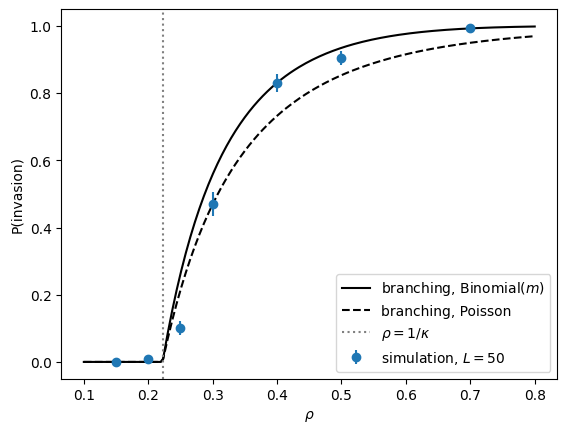

In [ ]:
rr = np.linspace(0.1, 0.8, 200)
plt.plot(rr, [q_invade(r * kappa, m) for r in rr], 'k-',  label='branching, Binomial($m$)')
plt.plot(rr, [q_invade(r * kappa)    for r in rr], 'k--', label='branching, Poisson')
plt.errorbar(rho_vals, p_sim, yerr=p_err, fmt='o', label='simulation, $L=50$')
plt.axvline(1 / kappa, color='grey', ls=':', label=r'$\rho = 1/\kappa$')
plt.xlabel(r'$\rho$'); plt.ylabel('P(invasion)')
plt.savefig("image")
plt.legend(); plt.show() 

This plot makes the following three things real:
1. The threshold is real.
Below ρ = 1/κ ≈ 0.22, invasion essentially never happens. Above it, P(invasion) rises steeply from zero, with a kink at the threshold, which is the signature of a transcritical bifurcation. The R₀ = ρκ criterion holds.

2. Above the threshold, invasion is still not guaranteed.
At ρ = 0.3, R₀ = 1.35 so the population should grow on average, yet about half of single introductions die out. This is demographic stochasticity: one founder can have zero offspring by chance before the lineage takes off. It is importamt to mention that mean-field theory says “R₀ > 1 means it grows” and misses this entirely. In invasion biology this is called propagule pressure: with n independent seeds the chance of success is 1 − (1−q)ⁿ, so at ρ = 0.3 five seeds give about 97%. 

3. Binomial beats Poisson because of offspring variance.
Near the threshold, q ≈ 2(R₀ − 1)/σ², where σ² is the variance in offspring number. A trap has at most m = 5 attempts, so its offspring count is Binomial with σ² = R₀(1 − R₀/m), which is less than the Poisson σ² = R₀. Lower variance means fewer unlucky early extinctions, so the probability is higher. The simulation follows the Binomial curve for ρ ≥ 0.4. The fact that the point at 0.3 sits on the Poisson curve should be a coincidence, not an agreement or proof that poisson distribution has a lower invariance.

4. Near the threshold the simulation falls below both curves.
At ρ = 0.25 the theory gives 0.26 and the simulation gives 0.10. The following is beleived to be the reason: Near R₀ = 1, q depends very steeply on R₀, so a small loss of offspring matters a lot. Using the approximation above, a simulated value of 0.10 corresponds to R₀,eff ≈ 1.04 rather than 1.125, which is about 7% fewer effective offspring per firing. The cause is locality: attempts collide on the same target, or land on the trap that fired the parent, which is already spent. This is the same mechanism behind the +0.10 onset shift in Notebook 3 and the κ_eff < κ result in the README. Over the first few generations it amounts to an apparent threshold slightly above 1/κ, roughly 0.23–0.24 in the plot.

5. The ρ = 0.2 point (0.01) is an artifact of the criterion.
At R₀ = 0.9 a subcritical cascade has mean total size 1/(1 − R₀) = 10 traps but a long tail, so about 1% of runs reach n_c = 50 and get counted as “invaded” even though they die later. Raising n_c or t_c would push this point to zero.

A summary of this section is the following:
R₀ = ρκ sets whether invasion is possible. The branching-process q sets how likely it is, with the Binomial form preferred because m is small. Spatial locality lowers the effective R₀ near the threshold and shifts it slightly upward.

## 5.4) **Long-term state:** does the population settle at an equilibrium, oscillate, or go extinct?

Once a seed has invaded, the long-term behaviour depends on the re-arming rate $p_{\text{regen}}$.

**Mean-field fixed point.** Write $s, i, r$ for the fractions of the lattice that are armed, firing and spent. A stationary state of the map in 5.1 must satisfy
$$
i^* = s^*\left(1 - e^{-\kappa i^*}\right), \qquad r^* = \frac{i^*}{p_{\text{regen}}}, \qquad s^* + i^* + r^* = \rho .
$$
The first condition says each firing trap exactly replaces itself. For small $i^*$, $1 - e^{-\kappa i^*} \approx \kappa i^*$, so
$$
s^* \approx \frac{1}{\kappa}, \qquad i^* \approx \frac{p_{\text{regen}}}{1 + p_{\text{regen}}}\left(\rho - \frac{1}{\kappa}\right).
$$
So the population **regulates its own resource**. It eats the armed traps down to the replacement level $1/\kappa$, which is the same number as the invasion threshold, whatever $\rho$ is. Increasing $\rho$ raises $i^*$, not $s^*$. In ecology this is the "$R^* $ rule"; in epidemiology it is the statement that the endemic susceptible fraction is $1/R_0$.

**Stability and oscillations.** Linearise the map about $(s^*, i^*)$, eliminating $r = \rho - s - i$. The Jacobian has a complex-conjugate pair of eigenvalues $\lambda$, and $|\lambda| < 1$. Deviations therefore decay as $|\lambda|^t$ and oscillate with period $T = 2\pi / |\arg\lambda|$. These are **damped boom–bust cycles**: armed traps build up, an outbreak follows, armed traps are depleted, the outbreak collapses, and the cycle repeats.

**Burnout.** The first outbreak overshoots: it consumes far more armed traps than the equilibrium needs, and $i$ then crashes to a deep minimum. Mean-field has no trouble with this, because $i$ is continuous and never reaches zero. On a lattice the population is a whole number of traps. If the minimum of the mean-field $i$ corresponds to fewer than about one trap, the population goes extinct in that first trough. The prediction is that persistence is controlled by **the number of firing traps at the first trough**, $L^2\, i_{\min}$, not just by $\rho\kappa > 1$.

**Possible outcomes for a single run:**
1. Early extinction: the seed fails to invade (section 5.3).
2. Burnout: it invades, then dies in the first trough.
3. Persistence: damped oscillations settle at the endemic state $(s^*, i^*)$.

In [19]:
from scipy.optimize import brentq

rho_lt = 0.8

def fixed_point(rho, kappa, p_regen):
    g = lambda i: i / (1 - np.exp(-kappa * i)) + i * (1 + 1 / p_regen) - rho
    i = brentq(g, 1e-12, rho)
    s = i / (1 - np.exp(-kappa * i))
    return s, i, i / p_regen

def jacobian_eigs(rho, kappa, p_regen):
    s, i, r = fixed_point(rho, kappa, p_regen)
    e = np.exp(-kappa * i)
    J = np.array([[e - p_regen,  -s * kappa * e - p_regen],
                  [1 - e,         s * kappa * e]])
    return np.linalg.eigvals(J)

In [20]:
def classify_run(history, t_burn=100, t_early=8):
    """Label one run and return the diagnostics."""
    i = np.array([np.sum(s == 1) for s in history]) / history[0].size
    T = len(i) - 1
    if i[-1] == 0:
        return dict(label='early extinction' if T < t_early else 'burnout', t_ext=T)
    if T <= t_burn + 20:
        raise ValueError("run too short: increase steps")

    x = i[t_burn:] - i[t_burn:].mean()
    acf = np.correlate(x, x, 'full')[len(x) - 1:]
    acf /= acf[0]
    freqs = np.fft.rfftfreq(len(x))
    power = np.abs(np.fft.rfft(x)) ** 2
    k = np.argmax(power[1:]) + 1
    half = len(x) // 2

    return dict(label='persist',
                mean_i=i[t_burn:].mean(),
                std_i=x.std(),
                amp_ratio=x[half:].std() / x[:half].std(),   # ~1 -> stationary
                acf_min=acf[1:40].min(),                     # < 0 -> oscillatory
                period=1 / freqs[k])                         # compare with mean-field

L=30  std(i)=0.0120  std*L=0.359  period=13.6  acf_min=-0.47  amp_ratio=0.91
L=50  std(i)=0.0076  std*L=0.381  period=13.1  acf_min=-0.55  amp_ratio=0.95
L=80  std(i)=0.0045  std*L=0.356  period=12.8  acf_min=-0.53  amp_ratio=1.17
mean-field: |lambda|=0.907  period=12.5


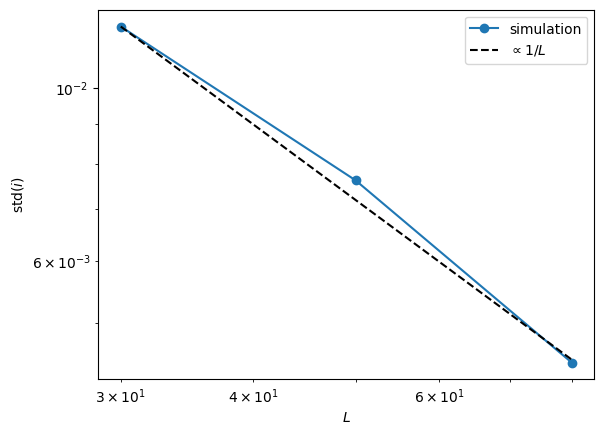

In [24]:
# Scaling test: limit cycle vs noise-driven quasi-cycles
L_vals, n_rep, p_test = (30, 50, 80), 3, 0.1
rng = np.random.default_rng(5)
amp = {}
for L in L_vals:
    res = []
    while len(res) < n_rep:
        h = regen_history(rho_lt, f_k, p_succ_long, p_long=p_long, m=m,
                          p_regen=p_test, L=L, steps=400, rng=rng)
        r = classify_run(h)
        if r['label'] == 'persist':
            res.append(r)
    amp[L] = np.mean([r['std_i'] for r in res])
    print(f"L={L}  std(i)={amp[L]:.4f}  std*L={amp[L]*L:.3f}  "
          f"period={np.mean([r['period'] for r in res]):.1f}  "
          f"acf_min={np.mean([r['acf_min'] for r in res]):.2f}  "
          f"amp_ratio={np.mean([r['amp_ratio'] for r in res]):.2f}")

lam = jacobian_eigs(rho_lt, kappa, p_test)[0]
print(f"mean-field: |lambda|={abs(lam):.3f}  period={2*np.pi/abs(np.angle(lam)):.1f}")

fig, ax = plt.subplots()
ax.loglog(L_vals, [amp[L] for L in L_vals], 'o-', label='simulation')
ax.loglog(L_vals, amp[L_vals[0]] * L_vals[0] / np.array(L_vals), 'k--', label=r'$\propto 1/L$')
ax.set_xlabel('$L$'); ax.set_ylabel(r'std$(i)$'); ax.legend()
fig.savefig("image2.png", dpi=200, bbox_inches='tight')   # save BEFORE show
plt.show()

**Result.** The measured amplitude falls as $L$ increases and lies close to the $L^{-1}$ reference line. This matches the quasi-cycle prediction: the oscillation is sustained by finite-size demographic noise and should vanish as $L \to \infty$. It is not a deterministic limit cycle.

Although it looks initially promising, it can be improved in two distinct ways:

- **The reference line is not a fit.** The dashed line $\propto 1/L$ is drawn through the $L = 30$ point by construction, so the agreement there is automatic. Only the positions of the $L = 50$ and $L = 80$ points relative to the line carry information. The small excess at $L = 50$ is within the run-to-run scatter of 3 runs.
- **There are no error bars.** Each point is the mean of only 3 surviving runs, and three such points cannot distinguish a slope of $-1$ from, say, $-0.8$. The plot is *consistent with* $L^{-1}$ but does not yet *measure* the exponent.

To turn this into a measurement, the next cell stores the amplitude of every run, adds standard-error bars, and fits the exponent directly by weighted least squares in log–log space.

In [26]:
L_vals, n_rep, p_test = (30, 50, 80), 3, 0.1
rng = np.random.default_rng(5)
amp, amp_runs = {}, {}                                
for L in L_vals:
    res = []
    while len(res) < n_rep:
        h = regen_history(rho_lt, f_k, p_succ_long, p_long=p_long, m=m,
                          p_regen=p_test, L=L, steps=400, rng=rng)
        r = classify_run(h)
        if r['label'] == 'persist':
            res.append(r)
    amp_runs[L] = [r['std_i'] for r in res]             
    amp[L] = np.mean(amp_runs[L])
    print(f"L={L}  std(i)={amp[L]:.4f}  std*L={amp[L]*L:.3f}")

L=30  std(i)=0.0120  std*L=0.359
L=50  std(i)=0.0076  std*L=0.381
L=80  std(i)=0.0045  std*L=0.356


slope = -1.00 ± 0.13   (quasi-cycles: -1, limit cycle: 0)


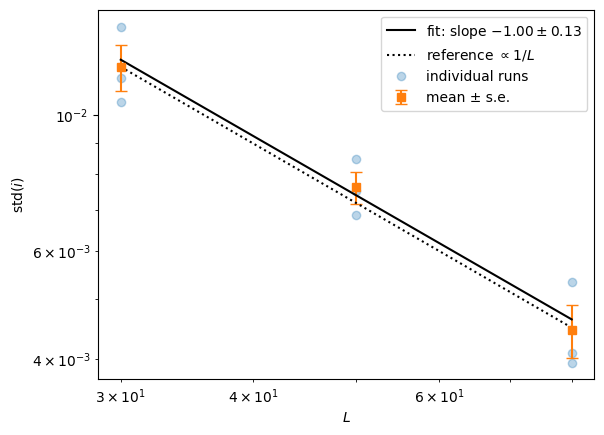

In [30]:
Ls = np.array(L_vals, float)
mu = np.array([np.mean(amp_runs[L]) for L in L_vals])
se = np.array([np.std(amp_runs[L], ddof=1) / np.sqrt(len(amp_runs[L])) for L in L_vals])

# weighted fit: log std = a + b log L
(b, a), cov = np.polyfit(np.log(Ls), np.log(mu), 1, w=mu / se, cov='unscaled')
db = np.sqrt(cov[0, 0])
print(f"slope = {b:.2f} ± {db:.2f}   (quasi-cycles: -1, limit cycle: 0)")

fig, ax = plt.subplots()
for L in L_vals:                                                        # individual runs
    ax.plot([L] * len(amp_runs[L]), amp_runs[L], 'o', color='C0', alpha=0.3)
ax.errorbar(Ls, mu, yerr=se, fmt='s', color='C1', capsize=4, label='mean ± s.e.')
LL = np.geomspace(Ls.min(), Ls.max(), 50)
ax.plot(LL, np.exp(a) * LL**b, 'k-', label=fr'fit: slope ${b:.2f} \pm {db:.2f}$')
ax.plot(LL, mu[0] * Ls[0] / LL, 'k:', label=r'reference $\propto 1/L$')
ax.plot([], [], 'o', color='C0', alpha=0.3, label='individual runs')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('$L$'); ax.set_ylabel(r'std$(i)$'); ax.legend()
fig.savefig("image3.png", dpi=200, bbox_inches='tight')
plt.show()

**The result can be defined as the following:** 
The weighted fit gives
$$
\operatorname{std}(i) \propto L^{\,b}, \qquad b = -1.00 \pm 0.13 .
$$
This agrees with the quasi-cycle prediction $b = -1$ (amplitude $\propto N^{-1/2}$). It is inconsistent with a deterministic limit cycle ($b = 0$) at about $7.7\sigma$. The other diagnostics agree:
- The runs are stationary: the early/late amplitude ratio is $\approx 1$.
- They are oscillatory: the autocorrelation has a negative lobe.
- Their period ($\approx 13$ generations) matches the mean-field damped mode, $2\pi/|\arg\lambda| = 12.5$.

**Interpretation.** The endemic state is a **stable fixed point**, as mean-field predicts ($|\lambda| = 0.91 < 1$). The oscillations seen in every surviving run are not part of the deterministic dynamics. Demographic noise, the randomness of which individual traps fire, keeps re-exciting the damped mode of the fixed point at its natural frequency. As $L \to \infty$ the noise vanishes and so do the oscillations.

So which three .............. :
- in the thermodynamic limit, the population **settles at an equilibrium**, with $s^* \approx 1/\kappa$;
- on any finite lattice, it **oscillates** around that equilibrium with amplitude $\propto L^{-1}$;
- if the first trough is too deep, it **goes extinct** first (burnout).

**Limitations.**
- Only 3 runs per $L$ and 3 lattice sizes spanning a factor of $2.7$, so the fit has a single degree of freedom.
- One parameter point was tested ($\rho = 0.8$, $p_{\text{regen}} = 0.1$).
- A wider range of $L$ and more runs would tighten the exponent.

## 5.5) **Regulation:** at equilibrium the armed density should settle near $S^* \approx 1/\kappa$, the level at which each firing trap exactly replaces itself.

## 5.6) **Stochastic extinction:** on a finite lattice a population that mean-field theory says should persist can die out by chance.